## Which Inputs Predict the Mean Execution Time on the Second Campaign, and How Strongly Does Each One Matter?

**Question.** `explain_7` compared input sets of the per-service GP on the first testbed campaign. This notebook asks
the same question on the second campaign, `statics/results_milos_v2/`, and adds a second one: how strongly is each
input associated with the mean execution time once the other inputs are held fixed? Section 4 repeats the GPs with
one length scale per input (ARD) and reads the relevance of every input from the fitted kernels.

Symbols: $Y$ is the execution time of one item (ms, from the start to the end of its processing) and $m$ the mean of $Y$
over the items of one run (`processing_mean_ms`). Inputs of the GP:
- *quality knobs*, which change the work per item: `data_quality` for every service, and `model_size` for the
  cv-analyzer;
- $r$, `cores`: the CPU quota of the container (cores); $c$, `parallelism`: the number of workers;
- $r / c$, the cores per worker: a single number for the CPU share that one busy worker can get;
- $\lambda$, the load: the measured arrival rate at the service in that run (items/s, `rate_received`).

**The second campaign.** Five experiments, each a chain of three services that process items in FIFO order:
`b1-audio-1`, `b1-vision-1` and `b1-lidar-1`. Each chain was measured as `-single` (one worker, $r \in \{1, 1.5, 2\}$)
and, except lidar, as `-workers` ($r$ from 1 to 4, $c$ from 1 to 4); every experiment has 150 runs at random
configurations, and the quality knob `data_quality` is shared by the three services of a run. One data point is one run
of one service; the runs of the `-single` and `-workers` experiments of a service are pooled. The lidar services were
only run with one worker, so for them $c$ is constant, $r / c = r$, and input sets that differ only in $c$ are the same.

The functions used here are in `pegasus/input_sets.py`, the same as for `explain_7`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr, wilcoxon

from pegasus.input_sets import (CAMPAIGN_V2, cross_validate_all, holm_adjusted, input_associations, mse_per_service, range_effect,
                                replicate_scatter, service_runs, services)

plt.style.use("default")
campaign = CAMPAIGN_V2
runs = {service: service_runs(service, campaign) for service in services(campaign)}
names = {service: service.split(":")[0] for service in runs}   # short names for the figures
sizes = pd.Series({service: len(table) for service, table in runs.items()})
display(Markdown(f"The campaign has {len(runs)} services with between {sizes.min()} and {sizes.max()} runs each."))

The campaign has 9 services with between 150 and 300 runs each.

### 1. How the Load Was Set, and Why It Matters

The second campaign does not choose the arrival rate at random: before a run, it probes the services and sets $\lambda$
so that the slowest service of the chain runs at a utilization of 0.5 (`load: {utilization: 0.5}` in
`experiment.yaml`). For a slowest service with $c$ workers, utilization $= \lambda\, m / c$, so the campaign sets
$\lambda \approx 0.5\, c / m_\text{slowest}$. Two consequences:
- **The load is a consequence of the execution time, not a cause.** A run with a slow configuration gets a low rate.
  A GP that sees $\lambda$ is therefore given a noisy copy of what it is asked to predict, at least for the slowest
  service; the other services of the chain share `data_quality` with it, so their execution times are correlated with
  $\lambda$ as well.
- **In a test of conditional independence, $\lambda$ must not be conditioned on blindly.** Conditioning on a
  consequence of the target can create associations between inputs and target that do not exist (Section 3).

**The figure below** has one panel per service. Horizontal axis: the load $\lambda$ (items/s); vertical axis: the run
mean $m$ (ms); both logarithmic; one point per run, the `-single` and `-workers` experiments in different markers. A
point cloud along a falling line means the load is determined by the execution time.

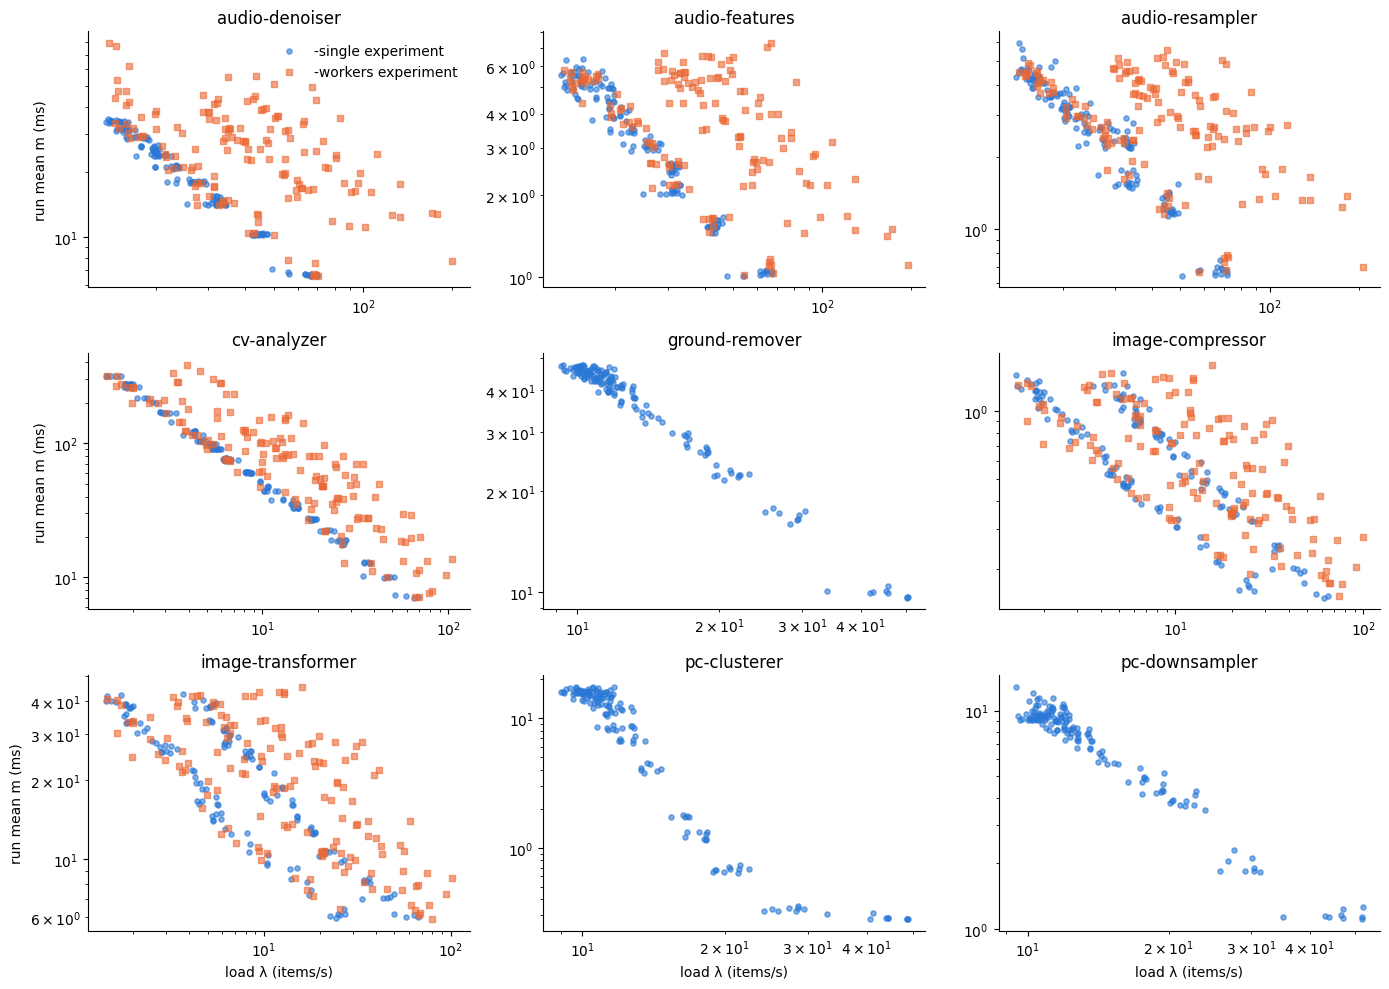

In [2]:
# Source: statics/results_milos_v2 (dataset.csv of every experiment), valid runs
experiment_styles = {"single": ("#2a78d6", "o"), "workers": ("#eb6834", "s")}
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, (service, table) in zip(axes.ravel(), runs.items()):
    for kind, (color, marker) in experiment_styles.items():
        chosen = table["experiment"].str.endswith(kind)
        if chosen.any():
            ax.scatter(table.loc[chosen, "load"], table.loc[chosen, "mean_ms"], s=14, alpha=0.6, color=color, marker=marker,
                       label=f"-{kind} experiment")
    ax.set(xscale="log", yscale="log", title=names[service])
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("load λ (items/s)")
for ax in axes[:, 0]:
    ax.set_ylabel("run mean m (ms)")
axes[0, 0].legend(frameon=False)
fig.tight_layout()
plt.show()

In [3]:
load_correlation = pd.Series({service: spearmanr(np.log(table["load"]), np.log(table["mean_ms"]))[0] for service, table in runs.items()})
display(Markdown(f"**What this shows.** The rank correlation between λ and m lies between {load_correlation.min():.2f} "
                 f"({names[load_correlation.idxmin()]}) and {load_correlation.max():.2f} ({names[load_correlation.idxmax()]}) "
                 f"over the services: the slower the configuration, the lower the load that the campaign chose."))

**What this shows.** The rank correlation between λ and m lies between -0.93 (ground-remover) and -0.53 (audio-denoiser) over the services: the slower the configuration, the lower the load that the campaign chose.

### 2. Six Input Sets for the Same GP

All input sets use the same model and the same splits as in `explain_7`; only the inputs differ.

- **2a. Quality knobs only:** the GP does not see the resources.
- **2b. Quality knobs and cores:** $r$ only.
- **2c. Quality knobs, cores and parallelism:** $r$ and $c$ as two inputs.
- **2d. Quality knobs, cores, parallelism and load:** 2c and $\lambda$.
- **2e. Quality knobs and cores per worker:** $r / c$ as one input.
- **2f. Quality knobs, cores per worker and load:** 2e and $\lambda$.
- **2g. Results:** the cross-validated error of the six input sets per service, and tests of the differences.

**Model.** The center GP of `RunStatisticsModel` (`service_gp.py`) as it was before 2026-10-14: a Matérn GP
($\nu = 2.5$) with one length scale for all inputs (`train_gp_models` with `ard=False`; lower limit `MIN_LENGTH_SCALE`) and a white-noise term, fitted to $\ln m$; its prediction is exponentiated. The inputs
are standardized. The hyperparameter search has 2 random restarts, as in `explain_7`.

**Cross-validation.** Five folds, grouped by the full configuration of the service (quality knobs, $r$ and $c$), so
that no held-out configuration occurs in the training data, also not for the input sets that cannot tell
configurations apart that differ only in $r$ or $c$; repeated with three seeds. All input sets use the same folds.

The setup cell below holds the container `results`, input set → one row per service, seed and fold (`cross_validate`
in `input_sets.py`). `cross_validate_all` reads the results from `statics/input_sets/results_milos_v2/` if they exist;
`recompute=True` computes them again.

In [4]:
results = {}   # input set -> DataFrame with one row per service, seed and fold

#### 2a. Quality Knobs Only

The GP sees only the knobs that change the work per item. Runs that differ only in $r$ or $c$ have the same input, so any effect of the resources on the execution time remains as error.

In [5]:
results["quality"] = cross_validate_all("quality", campaign)

#### 2b. Quality Knobs and Cores

The GP sees the CPU quota $r$ but not how many workers share it.

In [6]:
results["cores"] = cross_validate_all("cores", campaign)

#### 2c. Quality Knobs, Cores and Parallelism

The GP sees $r$ and $c$ as two inputs and can learn any dependence on the two, including the ratio of 2e, but has to learn it from the data with one length scale for all standardized inputs.

In [7]:
results["cores_and_parallelism"] = cross_validate_all("cores_and_parallelism", campaign)

#### 2d. Quality Knobs, Cores, Parallelism and Load

2c and the load $\lambda$. Because of Section 1, a gain from $\lambda$ does not show that the load changes the execution time: $\lambda$ was set from the measured execution time of the slowest service.

In [8]:
results["with_load"] = cross_validate_all("with_load", campaign)

#### 2e. Quality Knobs and Cores per Worker

The resources enter as one number, $r / c$. The idea: when all $c$ workers are busy, each gets at most $r / c$ cores, so 2 cores with 2 workers behave like 1 core with 1 worker. The input cannot describe effects that do not follow this ratio, e.g. that a worker can use only a limited number of cores however large $r / c$ is.

In [9]:
results["cores_per_worker"] = cross_validate_all("cores_per_worker", campaign)

#### 2f. Quality Knobs, Cores per Worker and Load

2e and the load $\lambda$, with the same caveat as in 2d.

In [10]:
results["cores_per_worker_with_load"] = cross_validate_all("cores_per_worker_with_load", campaign)

#### 2g. Results

**Metrics**, as in `explain_7`: per service, the squared errors of all held-out runs of one seed are pooled over the
five folds, and the three seeds are averaged.
- *Normalized MSE*: the MSE (ms²) divided by the variance of the held-out run means within their fold (ms²); 1 means
  "as good as predicting the average of the held-out runs", 0 means perfect. It makes services with mean execution
  times of a millisecond and of hundreds of milliseconds comparable; between two input sets of the same service, the
  ratio of the normalized MSEs equals the ratio of the MSEs.
- *MSE of the logarithm*: the mean of $(\ln \hat m - \ln m)^2$, where $\hat m$ is the prediction; for small errors
  the mean squared relative error (0.01 ≈ a typical error of 10%). It is not dominated by the slowest runs.

**The figure below** has one row per service (sorted by the normalized MSE of 2a) and one marker per input set; the
horizontal axes are logarithmic and lower is better. *Left:* normalized MSE. *Right:* MSE of the logarithm; the black
bars are the run-to-run scatter (`replicate_scatter`): the variance of $\ln m$ between runs of the same full
configuration, which a model with only the knobs as inputs cannot beat on average. Look at how far the resource input
sets (2b, 2c, 2e) move left of 2a, whether 2c and 2e differ, and whether the load (2d, 2f) moves a marker below the
black bar.

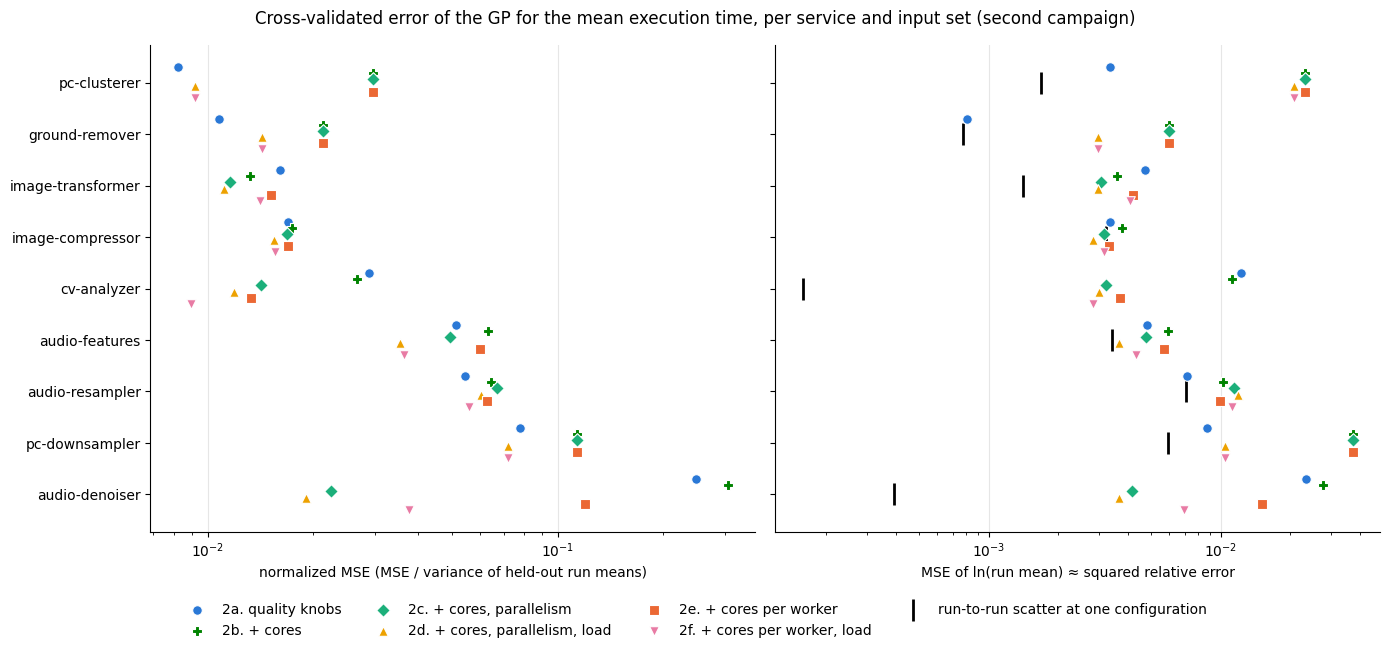

In [11]:
# Source: statics/results_milos_v2 (dataset.csv of every experiment), cross-validation of 2a-2f
styles = {"quality": ("2a. quality knobs", "#2a78d6", "o"),
          "cores": ("2b. + cores", "#008300", "P"),
          "cores_and_parallelism": ("2c. + cores, parallelism", "#1baf7a", "D"),
          "with_load": ("2d. + cores, parallelism, load", "#eda100", "^"),
          "cores_per_worker": ("2e. + cores per worker", "#eb6834", "s"),
          "cores_per_worker_with_load": ("2f. + cores per worker, load", "#e87ba4", "v")}
errors = mse_per_service(pd.concat(results.values(), ignore_index=True))
table = {metric: errors.pivot(index="service", columns="input_set", values=metric)[list(results)] for metric in ("nmse", "mse_log")}
order = table["nmse"]["quality"].sort_values().index
min_repeated = 5   # configurations with repeated runs that a service needs for its run-to-run scatter to be shown
scatter = pd.DataFrame([replicate_scatter(service, campaign) for service in order], index=order, columns=["variance", "configurations"])
scatter = scatter[scatter["configurations"] >= min_repeated]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
for ax, metric, xlabel in zip(axes, table, ["normalized MSE (MSE / variance of held-out run means)", "MSE of ln(run mean) ≈ squared relative error"]):
    for k, (name, (label, color, marker)) in enumerate(styles.items()):
        ax.scatter(table[metric].loc[order, name], np.arange(len(order)) + (k - 2.5) * 0.12, s=48, color=color, marker=marker,
                   edgecolor="white", linewidth=0.8, label=label, zorder=3)
    ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", which="major", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].scatter(scatter["variance"], [list(order).index(service) for service in scatter.index], marker="|", s=260, color="black",
                linewidth=2, label="run-to-run scatter at one configuration", zorder=2)
axes[0].set_yticks(np.arange(len(order)), [names[service] for service in order])
axes[0].invert_yaxis()
handles = axes[0].get_legend_handles_labels()[0] + axes[1].get_legend_handles_labels()[0][-1:]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Cross-validated error of the GP for the mean execution time, per service and input set (second campaign)")
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

**Tests.** For each pair of input sets, the ratio of their MSEs is computed per service, and a Wilcoxon signed-rank
test asks whether the logarithms of these ratios are centered at 0 (no difference). Assumptions: the services are
independent of each other (the three services of a chain share their runs and `data_quality`, so this holds only
approximately), and the log ratios are symmetric around their median. With as few values as there are services, the
test detects only a consistent difference.

In [12]:
pairs = [("cores", "quality"), ("cores_and_parallelism", "cores"), ("cores_per_worker", "quality"),
         ("cores_and_parallelism", "cores_per_worker"), ("with_load", "cores_and_parallelism"),
         ("cores_per_worker_with_load", "cores_per_worker")]

def comparison(metric: str, better: str, worse: str) -> str:
    ratio = table[metric][better] / table[metric][worse]
    return (f"{np.exp(np.log(ratio).median()):.2f}× in the median service, lower in {(ratio < 1).sum()} of {len(ratio)} services, "
            f"Wilcoxon p = {wilcoxon(np.log(ratio)).pvalue:.3f}")

short = {name: label.split(". ")[0] for name, (label, _, _) in styles.items()}
no_load = ["quality", "cores", "cores_and_parallelism", "cores_per_worker"]
best = table["mse_log"][no_load].min(axis=1)   # MSE of the logarithm of the best input set without the load
display(Markdown("**What this shows** (MSE of input set A ÷ MSE of input set B; below 1: A is better).\n" + "\n".join(
    f"- **{short[a]} vs {short[b]}:** MSE {comparison('nmse', a, b)}; MSE of the logarithm {comparison('mse_log', a, b)}."
    for a, b in pairs)
    + f"\n- **Run-to-run scatter:** for the {len(scatter)} services with at least {min_repeated} repeated configurations, the best input set "
      f"without the load has an MSE of the logarithm of {np.median(best.loc[scatter.index] / scatter['variance']):.1f}× the scatter in the median "
      f"service (from {(best.loc[scatter.index] / scatter['variance']).min():.1f}× to {(best.loc[scatter.index] / scatter['variance']).max():.1f}×)."))

**What this shows** (MSE of input set A ÷ MSE of input set B; below 1: A is better).
- **2b vs 2a:** MSE 1.23× in the median service, lower in 2 of 9 services, Wilcoxon p = 0.055; MSE of the logarithm 1.24× in the median service, lower in 2 of 9 services, Wilcoxon p = 0.055.
- **2c vs 2b:** MSE 0.96× in the median service, lower in 5 of 9 services, Wilcoxon p = 0.094; MSE of the logarithm 0.85× in the median service, lower in 5 of 9 services, Wilcoxon p = 0.062.
- **2e vs 2a:** MSE 1.15× in the median service, lower in 3 of 9 services, Wilcoxon p = 0.570; MSE of the logarithm 1.18× in the median service, lower in 4 of 9 services, Wilcoxon p = 0.359.
- **2c vs 2e:** MSE 1.00× in the median service, lower in 4 of 9 services, Wilcoxon p = 0.312; MSE of the logarithm 0.96× in the median service, lower in 5 of 9 services, Wilcoxon p = 0.094.
- **2d vs 2c:** MSE 0.84× in the median service, lower in 9 of 9 services, Wilcoxon p = 0.004; MSE of the logarithm 0.89× in the median service, lower in 8 of 9 services, Wilcoxon p = 0.012.
- **2f vs 2e:** MSE 0.67× in the median service, lower in 9 of 9 services, Wilcoxon p = 0.004; MSE of the logarithm 0.77× in the median service, lower in 8 of 9 services, Wilcoxon p = 0.027.
- **Run-to-run scatter:** for the 9 services with at least 5 repeated configurations, the best input set without the load has an MSE of the logarithm of 1.5× the scatter in the median service (from 1.0× to 20.2×).

### 3. How Strongly Each Input Is Associated with the Mean Execution Time

**Method.** The test that constraint-based structure learning (e.g. the PC algorithm) uses to decide whether an edge
between two variables is needed: is input $X$ independent of $\ln m$ given the other inputs $Z$? For continuous data
this is a test of the *partial correlation* $\rho_\text{s}$ of $X$ and $\ln m$ given $Z$: both are regressed linearly on $Z$, and
$\rho_\text{s}$ is the correlation of the two residuals. $\rho_\text{s}$ is what is left of the association of $X$ with the execution time
after everything that $Z$ explains has been removed; $\rho_\text{s}^2$ is the share of the remaining variance of $\ln m$ that $X$
explains. The sign says whether a larger $X$ makes the service slower ($\rho_\text{s} > 0$) or faster ($\rho_\text{s} < 0$).

Details (`partial_correlation_test` in `input_sets.py`):
- **On ranks.** Every variable is replaced by its ranks before the regressions (Spearman partial correlation, the
  "nonparanormal" variant of the test). The effects here are monotone but not linear (e.g. more cores help less and
  less), and ranks are robust against the few very slow runs.
- **p-value.** Fisher's transform $\sqrt{n - |Z| - 3}\,\operatorname{atanh}(\rho_\text{s})$, with $n$ runs and $|Z|$ conditioning
  inputs, is standard normal under independence (as `gaussCItest` in pcalg and `fisherz` in causal-learn).
  Assumptions: the runs are independent, and the ranks are jointly Gaussian after the transform. The p-values of one
  panel are Holm-adjusted over all its cells, because many tests are made at once.
- **Conditioning set.** $Z$ is all other inputs, so $\rho_\text{s}$ measures the *direct* association of $X$ with the execution
  time. $r / c$ is a function of $r$ and $c$ and is tested in their place (given the quality knobs). For the lidar
  services, $c$ is constant and is left out.
- **With or without the load.** Section 1 showed that $\lambda$ is set from the execution time. Conditioning on such a
  consequence of the target changes the partial correlations of the other inputs: among runs with the same load, a
  configuration with more work per item must have been faster in some other way, which creates an association that
  the services do not have. The test is therefore made twice, without and with $\lambda$ among the inputs.

**Computation.**

In [13]:
associations = {with_load: pd.concat([input_associations(service, campaign, with_load) for service in runs], ignore_index=True)
                for with_load in (False, True)}
for table_ in associations.values():
    table_["p_holm"] = holm_adjusted(table_["p"])

**The figure below** has one heatmap per conditioning set: rows are services, columns are inputs, and the color
of a cell is the partial rank correlation $\rho_\text{s}$ of that input with $\ln m$ (red: a larger value of the input makes the
service slower; blue: faster; gray: no association). The number in a cell is $\rho_\text{s}$; a cell whose Holm-adjusted p-value is
above 0.05 is hatched (no evidence for an association); an empty cell is an input that the service does not have or
that was not varied. *Left:* inputs are the quality knobs, $r$ and $c$. *Right:* the same and the load $\lambda$. Look
at which inputs are dark in the left panel, and at which cells change color between the panels.

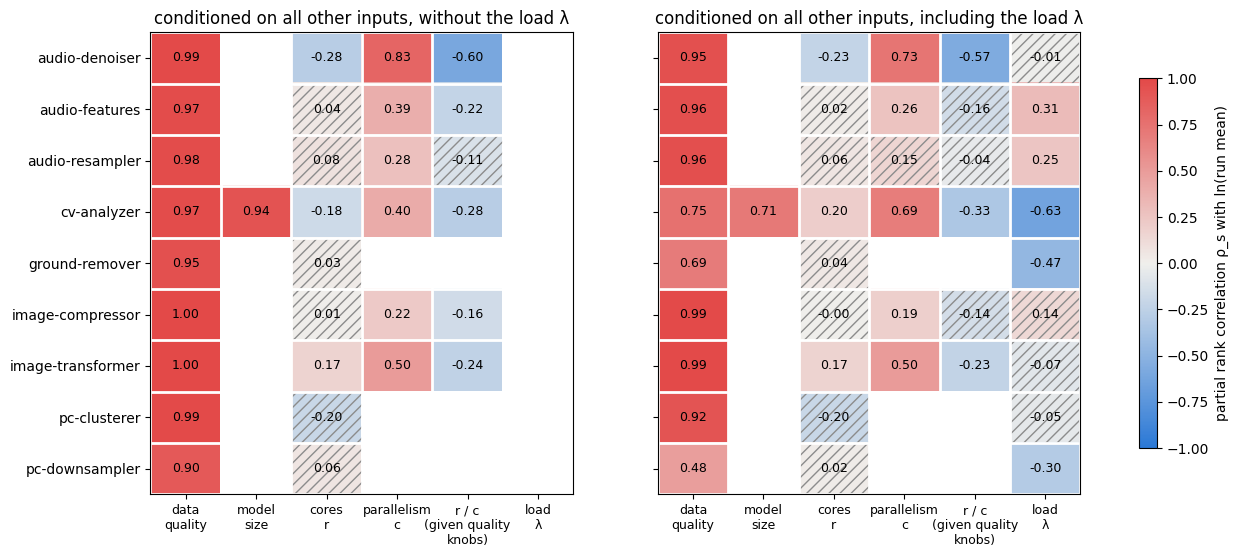

In [14]:
# Source: statics/results_milos_v2, partial rank correlations of Section 3
alpha = 0.05
columns = ["data_quality", "model_size", "cores", "parallelism", "cores_per_worker", "load"]
column_labels = ["data\nquality", "model\nsize", "cores\nr", "parallelism\nc", "r / c\n(given quality\nknobs)", "load\nλ"]
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
service_order = list(runs)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, (with_load, table_) in zip(axes, associations.items()):
    r = table_.pivot(index="service", columns="input", values="r").reindex(index=service_order, columns=columns)
    p = table_.pivot(index="service", columns="input", values="p_holm").reindex(index=service_order, columns=columns)
    image = ax.imshow(r.to_numpy(), cmap=diverging, vmin=-1, vmax=1, aspect="auto")
    for i in range(r.shape[0]):
        for j in range(r.shape[1]):
            if np.isnan(r.iat[i, j]):
                continue
            if p.iat[i, j] > alpha:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="///", edgecolor="0.55", linewidth=0))
            ax.text(j, i, f"{r.iat[i, j]:.2f}", ha="center", va="center", fontsize=9, color="black")
    ax.set_xticks(range(len(columns)), column_labels, fontsize=9)
    ax.set_title("conditioned on all other inputs, including the load λ" if with_load else "conditioned on all other inputs, without the load λ")
    ax.set_xticks(np.arange(len(columns) + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(service_order) + 1) - 0.5, minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)
axes[0].set_yticks(range(len(service_order)), [names[service] for service in service_order])
fig.colorbar(image, ax=axes, shrink=0.8, label="partial rank correlation ρ_s with ln(run mean)")
plt.show()

In [15]:
without, with_ = (associations[False].set_index(["service", "input"]), associations[True].set_index(["service", "input"]))
significant = without[without["p_holm"] <= alpha]
strongest = without.loc[without.groupby(level="service")["r"].apply(lambda r: r.abs().idxmax())]
shared = without.index.intersection(with_.index)
flipped = shared[(np.sign(without.loc[shared, "r"]) != np.sign(with_.loc[shared, "r"])) & (with_.loc[shared, "p_holm"] <= alpha)]

def summary(name: str) -> str:
    chosen = without.xs(name, level="input")
    return (f"median |r| {chosen['r'].abs().median():.2f} over the {len(chosen)} service(s) that have it, significant in "
            f"{(chosen['p_holm'] <= alpha).sum()}")

display(Markdown(
    f"**What this shows** (without the load; Holm-adjusted α = {alpha}).\n"
    + "\n".join(f"- **{name}:** {summary(name)}." for name in columns[:-1] if name in without.index.get_level_values("input"))
    + (f"\n- **Strongest input:** {strongest.index.get_level_values('input')[0]} in every service.\n"
       if strongest.index.get_level_values("input").nunique() == 1 else
       f"\n- **Strongest input per service:** " + ", ".join(f"{names[service]}: {name} ({r:+.2f})" for (service, name), r in strongest["r"].items()) + ".\n")
    + f"- **With the load among the inputs,** {len(flipped)} of the {len(shared)} associations that are tested in both panels change their "
      f"sign and are significant afterwards"
    + (": " + ", ".join(f"{name} of {names[service]}" for service, name in flipped) if len(flipped) else "") + "."))

**What this shows** (without the load; Holm-adjusted α = 0.05).
- **data_quality:** median |r| 0.98 over the 9 service(s) that have it, significant in 9.
- **model_size:** median |r| 0.94 over the 1 service(s) that have it, significant in 1.
- **cores:** median |r| 0.08 over the 9 service(s) that have it, significant in 3.
- **parallelism:** median |r| 0.39 over the 6 service(s) that have it, significant in 6.
- **cores_per_worker:** median |r| 0.23 over the 6 service(s) that have it, significant in 5.
- **Strongest input:** data_quality in every service.
- **With the load among the inputs,** 1 of the 31 associations that are tested in both panels change their sign and are significant afterwards: cores of cv-analyzer.

### 4. One Length Scale per Input (ARD)

The GPs of Section 2 have one length scale $\ell$ for all inputs (`Matern(length_scale=1.0)`): two
configurations are similar if their standardized inputs are close, and every input counts the same in that distance.
Section 2 found that adding an input without effect, e.g. the cores of the lidar services, makes the predictions worse,
and Section 3 that the inputs differ strongly in how much they matter. A kernel with one length scale $\ell_i$ per input
$i$ (*automatic relevance determination*, ARD) lets the hyperparameter search give an input that does not matter a long
length scale, so that it hardly changes the distance between two configurations.

- **4a. Computation:** the six input sets of Section 2 again, with ARD; everything else unchanged (same folds, kernel
  family, bounds, noise term and restarts; `train_gp_models` with `ard=True`). Inputs with the same value in every run of
  a service are left out, because their length scale cannot be learned. For an input set with a single input (2a for all
  services but the cv-analyzer), ARD and one length scale are the same model.
- **4b. Errors:** ARD compared with one length scale, and the input sets compared with each other under ARD.
- **4c. Length scales:** the fitted $\ell_i$ as a second measure of how much each input matters, next to the partial
  correlations of Section 3.

Since 2026-10-14, `train_gp_models` in `service_gp.py` uses ARD by default, so every GP of the method and the
evaluation has one length scale per input; Section 2 keeps one length scale for all inputs (`ard=False`) for the
comparison.

In [16]:
# 4a: the six input sets of Section 2 with one length scale per input (cached in statics/input_sets/results_milos_v2_ard/)
results_ard = {name: cross_validate_all(name, campaign, ard=True) for name in results}

#### 4b. Errors with One Length Scale per Input

**The figure below** has the rows, markers and logarithmic axes of 2g; lower is better. *Left:* the MSE of the
logarithm with ARD, with the run-to-run scatter as black bars (as in the right panel of 2g). *Right:* the MSE of the
logarithm with ARD ÷ the same with one length scale; left of the dashed line at 1, ARD is better. Look at whether the
resource input sets (2b, 2c, 2e) now reach or beat 2a, and at the lidar services, where one length scale was hurt most by
the cores.

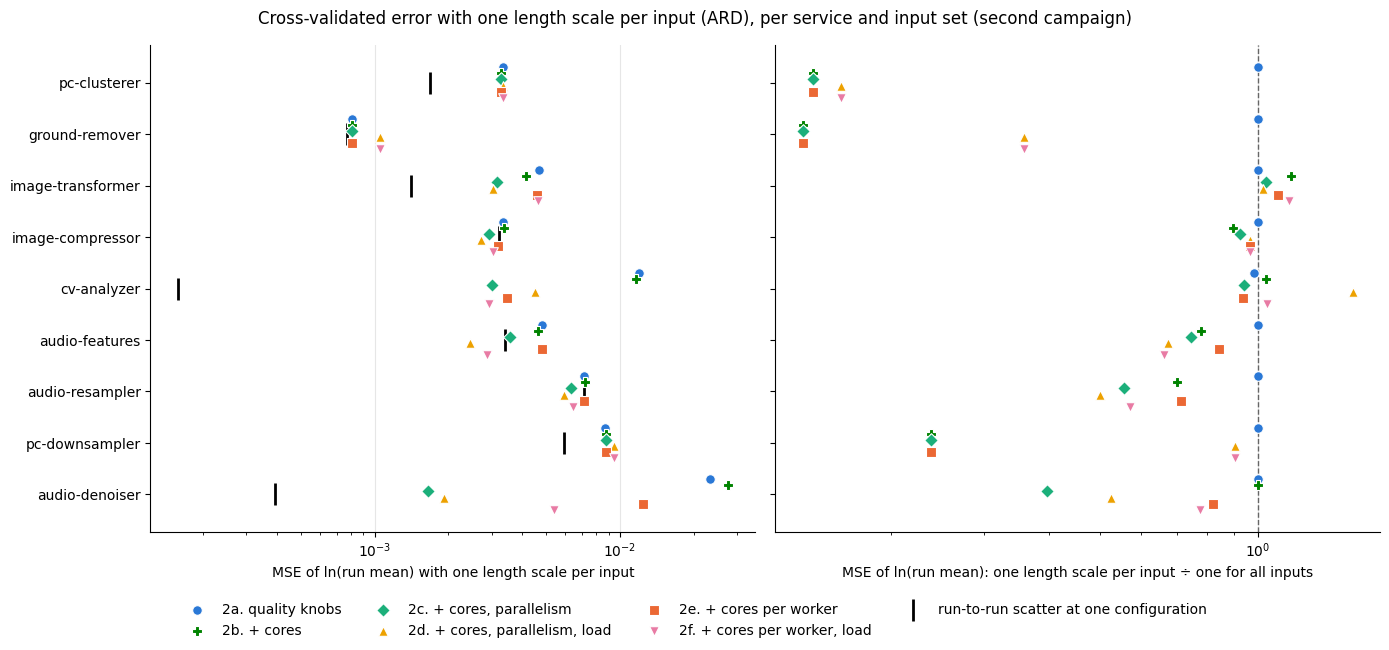

In [17]:
# Source: statics/results_milos_v2, cross-validation of 2a-2f with one length scale per input (4a) and with one for all (2g)
errors_ard = mse_per_service(pd.concat(results_ard.values(), ignore_index=True))
table_ard = {metric: errors_ard.pivot(index="service", columns="input_set", values=metric)[list(results_ard)] for metric in ("nmse", "mse_log")}
panels = [(table_ard["mse_log"], "MSE of ln(run mean) with one length scale per input"),
          (table_ard["mse_log"] / table["mse_log"], "MSE of ln(run mean): one length scale per input ÷ one for all inputs")]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
for ax, (values, xlabel) in zip(axes, panels):
    for k, (name, (label, color, marker)) in enumerate(styles.items()):
        ax.scatter(values.loc[order, name], np.arange(len(order)) + (k - 2.5) * 0.12, s=48, color=color, marker=marker,
                   edgecolor="white", linewidth=0.8, label=label, zorder=3)
    ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", which="major", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].scatter(scatter["variance"], [list(order).index(service) for service in scatter.index], marker="|", s=260, color="black",
                linewidth=2, label="run-to-run scatter at one configuration", zorder=2)
axes[1].axvline(1.0, color="0.4", linewidth=1, linestyle="--")
axes[0].set_yticks(np.arange(len(order)), [names[service] for service in order])
axes[0].invert_yaxis()
fig.legend(handles=axes[0].get_legend_handles_labels()[0], loc="lower center", ncol=4, frameon=False)
fig.suptitle("Cross-validated error with one length scale per input (ARD), per service and input set (second campaign)")
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

In [18]:
def paired(ratio: pd.Series) -> str:
    """Median ratio, count of services below 1 and Wilcoxon p over the services in which the two models differ. A ratio of
    exactly 1 means the same model: with a single input, ARD and one length scale coincide, and for the lidar services 2c
    is 2b, because the constant parallelism is left out."""
    ratio = ratio[~np.isclose(ratio, 1.0, rtol=1e-3)]   # within 0.1%: the same model up to the numerics of the fit
    if len(ratio) < 2:
        return "the same model in all but at most one service"
    return (f"{np.exp(np.log(ratio).median()):.2f}× in the median service, lower in {(ratio < 1).sum()} of {len(ratio)} services, "
            f"Wilcoxon p = {wilcoxon(np.log(ratio)).pvalue:.3f}")

display(Markdown(
    "**What this shows: ARD vs one length scale** (MSE with ARD ÷ MSE with one length scale; below 1: ARD is better).\n"
    + "\n".join(f"- **{short[name]}:** MSE {paired(table_ard['nmse'][name] / table['nmse'][name])}; "
                f"MSE of the logarithm {paired(table_ard['mse_log'][name] / table['mse_log'][name])}." for name in styles)
    + "\n\n**The input sets under ARD** (MSE of A ÷ MSE of B; below 1: A is better).\n"
    + "\n".join(f"- **{short[a]} vs {short[b]}:** MSE {paired(table_ard['nmse'][a] / table_ard['nmse'][b])}; "
                f"MSE of the logarithm {paired(table_ard['mse_log'][a] / table_ard['mse_log'][b])}." for a, b in pairs)))

**What this shows: ARD vs one length scale** (MSE with ARD ÷ MSE with one length scale; below 1: ARD is better).
- **2a:** MSE the same model in all but at most one service; MSE of the logarithm the same model in all but at most one service.
- **2b:** MSE 0.85× in the median service, lower in 6 of 9 services, Wilcoxon p = 0.129; MSE of the logarithm 0.74× in the median service, lower in 6 of 8 services, Wilcoxon p = 0.055.
- **2c:** MSE 0.82× in the median service, lower in 6 of 9 services, Wilcoxon p = 0.055; MSE of the logarithm 0.56× in the median service, lower in 8 of 9 services, Wilcoxon p = 0.008.
- **2d:** MSE 0.95× in the median service, lower in 5 of 9 services, Wilcoxon p = 0.250; MSE of the logarithm 0.68× in the median service, lower in 7 of 9 services, Wilcoxon p = 0.055.
- **2e:** MSE 0.87× in the median service, lower in 7 of 9 services, Wilcoxon p = 0.020; MSE of the logarithm 0.82× in the median service, lower in 8 of 9 services, Wilcoxon p = 0.020.
- **2f:** MSE 1.02× in the median service, lower in 4 of 9 services, Wilcoxon p = 0.734; MSE of the logarithm 0.78× in the median service, lower in 7 of 9 services, Wilcoxon p = 0.055.

**The input sets under ARD** (MSE of A ÷ MSE of B; below 1: A is better).
- **2b vs 2a:** MSE 1.01× in the median service, lower in 3 of 7 services, Wilcoxon p = 0.938; MSE of the logarithm 0.99× in the median service, lower in 4 of 8 services, Wilcoxon p = 0.641.
- **2c vs 2b:** MSE 0.78× in the median service, lower in 5 of 5 services, Wilcoxon p = 0.062; MSE of the logarithm 0.77× in the median service, lower in 6 of 6 services, Wilcoxon p = 0.031.
- **2e vs 2a:** MSE 1.00× in the median service, lower in 4 of 8 services, Wilcoxon p = 0.547; MSE of the logarithm 0.98× in the median service, lower in 7 of 8 services, Wilcoxon p = 0.039.
- **2c vs 2e:** MSE 0.77× in the median service, lower in 5 of 5 services, Wilcoxon p = 0.062; MSE of the logarithm 0.80× in the median service, lower in 6 of 6 services, Wilcoxon p = 0.031.
- **2d vs 2c:** MSE 0.94× in the median service, lower in 7 of 9 services, Wilcoxon p = 0.027; MSE of the logarithm 1.01× in the median service, lower in 4 of 9 services, Wilcoxon p = 0.570.
- **2f vs 2e:** MSE 0.93× in the median service, lower in 7 of 9 services, Wilcoxon p = 0.020; MSE of the logarithm 0.96× in the median service, lower in 5 of 9 services, Wilcoxon p = 0.359.

#### 4c. What the Fitted Kernels Say About Each Input

**Length scales alone are not a measure of relevance.** The inputs are standardized, so $\ell_i$ is measured in
standard deviations of input $i$. A long $\ell_i$ means that the prediction changes *smoothly* with input $i$: almost
linearly over the measured range. A smooth change can still be large if the signal variance $\sigma_f^2$ of the kernel
is large. Example: the cv-analyzer gets a long length scale for `model_size` (small numbers in the figure below),
although `model_size` is one of its strongest inputs in Section 3; the GP draws that effect as an almost straight line,
with a long length scale and a large $\sigma_f^2$.

**Range effect.** The figure below therefore combines both into one number per input (`range_effect` in
`input_sets.py`): the standard deviation, under the fitted kernel, of the difference between the predictions at the
smallest and at the largest training value of input $i$, all other inputs fixed,
$$\sqrt{2\,\sigma_f^2\,\bigl(1 - k(\Delta_i / \ell_i)\bigr)},$$
where $\Delta_i$ is the range of input $i$ in standard deviations and $k$ the Matérn correlation ($\nu = 2.5$). The GP
normalizes its target, so the unit is standard deviations of $\ln m$ in the training runs: 1 means that the GP lets
the prediction differ by about one standard deviation of $\ln m$ between the two ends of the input's range, 0 that the
GP ignores the input. Like the length scale, the range effect says nothing about the direction; the sign is in
Section 3. It describes what the fitted kernel allows, not a measured difference, and is best compared between the
inputs of one service (within a row): $\sigma_f^2$ differs between services.

**The figure below** has one heatmap per input set. Rows are services, columns are inputs, and each cell is the median
range effect over the 15 fits (5 folds × 3 seeds): dark means the input matters, light that it is practically
ignored; range effects above `color_limit` all get the darkest color. The number in a cell is the median range effect, and the small number below it the median length scale
$\ell_i$. An empty cell is an input that the service does not have or that was not varied. *Left:* input set 2c
(quality knobs, $r$, $c$). *Right:* 2d (the same and $\lambda$). Compare the light cells with the hatched cells of
Section 3.

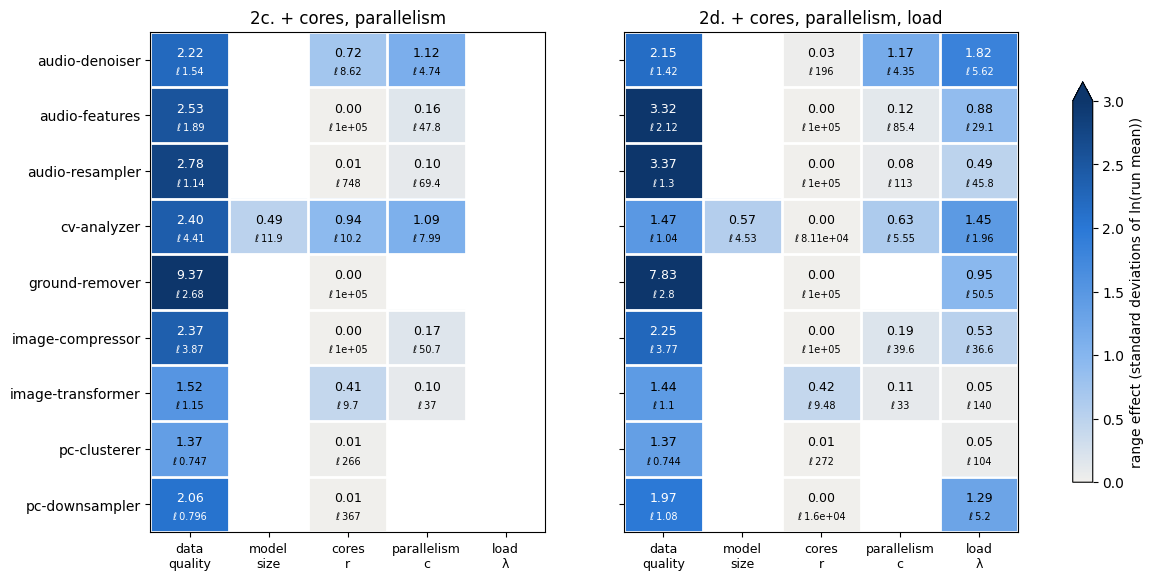

In [19]:
# Source: statics/results_milos_v2, kernels of the ARD fits of 4a
ignored_effect = 0.1   # standard deviations of ln(run mean); below this, the GP practically ignores an input
color_limit = 3.0      # standard deviations of ln(run mean); larger range effects get the darkest color
length_inputs = ["data_quality", "model_size", "cores", "parallelism", "load"]
length_labels = ["data\nquality", "model\nsize", "cores\nr", "parallelism\nc", "load\nλ"]
sequential = LinearSegmentedColormap.from_list("blue_ramp", ["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"])

def kernel_summary(name: str) -> tuple:
    """Median range effect and median length scale of every input (columns) per service (rows), input set `name`, ARD."""
    frame = results_ard[name]
    inputs = [column[len("length_scale_"):] for column in frame.columns if column.startswith("length_scale_")]
    effects = pd.DataFrame({i: range_effect(frame[f"length_scale_{i}"], frame[f"range_{i}"], frame["signal_variance"]) for i in inputs})
    effects["service"] = frame["service"]
    lengths = frame[["service"] + [f"length_scale_{i}" for i in inputs]].rename(columns=lambda column: column.replace("length_scale_", ""))
    shape = lambda table_: table_.groupby("service").median().reindex(index=service_order, columns=length_inputs)
    return shape(effects), shape(lengths)

kernels = {name: kernel_summary(name) for name in ("cores_and_parallelism", "with_load")}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
for ax, (name, (effects, lengths)) in zip(axes, kernels.items()):
    image = ax.imshow(effects.to_numpy(), cmap=sequential, vmin=0, vmax=color_limit, aspect="auto")
    for i in range(effects.shape[0]):
        for j in range(effects.shape[1]):
            if not np.isnan(effects.iat[i, j]):
                color = "white" if effects.iat[i, j] > 0.6 * image.norm.vmax else "black"
                ax.text(j, i - 0.12, f"{effects.iat[i, j]:.2f}", ha="center", va="center", fontsize=9, color=color)
                ax.text(j, i + 0.22, f"ℓ {lengths.iat[i, j]:.3g}", ha="center", va="center", fontsize=7, color=color)
    ax.set_xticks(range(len(length_inputs)), length_labels, fontsize=9)
    ax.set_title(styles[name][0])
    ax.set_xticks(np.arange(len(length_inputs) + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(service_order) + 1) - 0.5, minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)
axes[0].set_yticks(range(len(service_order)), [names[service] for service in service_order])
fig.colorbar(image, ax=axes, shrink=0.8, extend="max", label="range effect (standard deviations of ln(run mean))")
plt.show()

In [20]:
def effect_summary(effects: pd.DataFrame, name: str) -> str:
    chosen = effects[name].dropna()
    return (f"median range effect {chosen.median():.2f} over the {len(chosen)} service(s) that have it, practically ignored "
            f"(below {ignored_effect:g}) in {(chosen < ignored_effect).sum()}")

effects_2c, effects_2d = kernels["cores_and_parallelism"][0], kernels["with_load"][0]
display(Markdown(
    f"**What this shows** (input set {short['cores_and_parallelism']}, ARD).\n"
    + "\n".join(f"- **{name}:** {effect_summary(effects_2c, name)}." for name in length_inputs if effects_2c[name].notna().any())
    + f"\n\n**With the load** ({short['with_load']}): λ has a median range effect of {effects_2d['load'].median():.2f}; the median range "
      f"effect of `data_quality` changes from {effects_2c['data_quality'].median():.2f} to {effects_2d['data_quality'].median():.2f}."))

**What this shows** (input set 2c, ARD).
- **data_quality:** median range effect 2.37 over the 9 service(s) that have it, practically ignored (below 0.1) in 0.
- **model_size:** median range effect 0.49 over the 1 service(s) that have it, practically ignored (below 0.1) in 0.
- **cores:** median range effect 0.01 over the 9 service(s) that have it, practically ignored (below 0.1) in 6.
- **parallelism:** median range effect 0.16 over the 6 service(s) that have it, practically ignored (below 0.1) in 1.

**With the load** (2d): λ has a median range effect of 0.88; the median range effect of `data_quality` changes from 2.37 to 2.15.

### 5. What Follows

- **The quality knobs decide the mean execution time.** `data_quality` (and `model_size` of the cv-analyzer) is by
  far the strongest input of every service in Section 3, and the GP with the quality knobs alone (2a) is already
  accurate for most services in Section 2.
- **Of the resources, the number of workers matters more than the cores.** Given the other inputs, more workers make
  an item slower in every service that was run with several workers (workers share the CPU quota and the machine),
  and a larger $r / c$ makes it faster; the cores alone have a weak or no association once $c$ is known. For the lidar
  services, which only ran with one worker, the cores have no association at all: apparently one worker does not use
  more than the smallest quota of the campaign (1 core).
- **An input without effect makes the GP with one length scale worse; ARD removes that.** With one length scale
  for all inputs (Section 2), adding $r$ alone (2b) raises the error in most services, most clearly for the lidar
  services, where Section 3 finds no association of $r$ with the execution time. With one length scale per input
  (Section 4), the GP gives such an input a long length scale and a range effect near 0, adding $r$ no longer costs
  accuracy, and the relative error (MSE of the logarithm) of every input set with resources is lower with ARD in the
  median service (4b).
- **With ARD, cores and parallelism as two inputs are the best input set without the load.** Under ARD, 2c beats both
  $r$ alone (2b) and the ratio $r / c$ (2e) in the services that were run with several workers. The ratio alone is
  about as accurate as the quality knobs alone. Which inputs the ARD kernels keep (Section 4c) agrees with the partial
  correlations of Section 3: `data_quality` dominates, $c$ matters a little in most services, and $r$ is practically
  ignored except in the services where Section 3 finds an association.
- **The load cannot be judged on this campaign.** With one length scale, adding $\lambda$ (2d, 2f) lowers the error in
  every service; with ARD, the gain is smaller and no longer shows in the relative error. Either way, Section 1 shows
  why a gain is expected: the campaign set $\lambda$ from the execution time of the slowest service. For the same reason,
  conditioning on $\lambda$ in Section 3 takes over a part of the association of `data_quality` and changes the sign of
  the cores of the cv-analyzer; the right panel of the heatmap is not evidence for an effect of the load. Whether
  execution times depend on the load (Assumption 3 of Pegasus, `explain_6`) needs runs in which the load is varied
  independently of the configuration, as in the first campaign (`explain_7`).

Limits:
- The three services of a chain share their runs and `data_quality`, so the services are not independent samples
  for the Wilcoxon tests.
- The `-single` and `-workers` experiments of a service are pooled; their ranges of $r$ differ, and the lidar chain
  has no `-workers` experiment.
- The partial correlations measure monotone associations in the measured range of every input; an effect that
  reverses within the range (e.g. too many workers for the cores) can show a small $\rho_\text{s}$ although it is large.